# PneumoLens | Phase 2 — Exploratory Data Analysis
#### Single-dataset pediatric chest X-ray study · Kaggle-ready · reproducible outputs

**Purpose.** Profile the *actual* ZhangLab/Kermany pediatric chest X-ray copy used in Phase 1 before choosing preprocessing or training settings. Produce clear figures, quality checks, a research report, and **one structured ZIP** ready to extract into your Windows PneumoLens project.

**Run once:** Attach the same Kaggle dataset used for Phase 1, then select **Run All**. No external downloads, pretrained models, GPU, separate manifest, or manually created directory paths are required. The input-discovery cell stops with instructions if more than one plausible chest X-ray source exists.

> **Important boundaries:** This is EDA, **not** patient-level validation, a clinical study, or model training. Filename BACTERIA/VIRUS tags are *unverified dataset tokens*, not a pathogen diagnosis. The original test split is summarized by filenames and image headers only: **no test-set pixel intensity analysis, X-ray galleries, threshold fitting, or preprocessing tuning**. No train/validation/test partition is created here.

## 1 · Experiment contract and configuration

- **Source unit:** one file in a `chest_xray/{train|test|val}/{NORMAL|PNEUMONIA}/` folder. We do not assume a file equals a unique patient.
- **One source:** detect a single chest X-ray folder within Kaggle input (or a ZIP with the same structure); ignore unrelated OCT folders.
- **Reproducibility:** fixed RNG seed, saved parameters and library versions, deterministic inventory ordering.
- **Pixel sample:** *every readable training image*, reduced to a bounded 256-pixel-side thumbnail solely for descriptive intensity statistics; statistics are **approximate** for the original full-resolution images.
- **Test boundary:** record counts, file size, modes, and dimensions without running pixel statistics on the locked test images.
- **Safe export:** figures/tables/reports are suitable for project review; image-level identifiers and the X-ray gallery are placed under `data/processed/`, which your Git ignore rules exclude from GitHub.

**Overrides (rarely needed):** set `PNEUMOLENS_CXR_SOURCE` to an exact `chest_xray` directory or a dataset ZIP; set `PNEUMOLENS_INPUT_ROOT` to a local directory for non-Kaggle execution. The normal Kaggle path is discovered automatically.

In [1]:
from __future__ import annotations

import io
import json
import math
import os
import platform
import re
import sys
import warnings
import zipfile
from collections import Counter
from contextlib import contextmanager
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import FileLink, display
from PIL import Image, ImageOps, ImageFile
from tqdm.auto import tqdm

# -------- Only configuration cell normally relevant to the user --------
INPUT_ROOT = Path(os.environ.get('PNEUMOLENS_INPUT_ROOT', '/kaggle/input'))
SOURCE_OVERRIDE = os.environ.get('PNEUMOLENS_CXR_SOURCE', '').strip()
WORK_DIR = Path(os.environ.get('PNEUMOLENS_EDA_OUTPUT', '/kaggle/working/pneumolens_eda_phase02'))
SEED = 2026
MAX_ANALYSIS_SIDE = 256
MODEL_PREVIEW_SIDE = 224
EXAMPLES_PER_CLASS = 4

# Phase 1 audit reference. A mismatch creates a warning, never a silent relabel.
PHASE1_REFERENCE = {
    ('train', 'NORMAL'): 1349,
    ('train', 'PNEUMONIA'): 3883,
    ('test', 'NORMAL'): 234,
    ('test', 'PNEUMONIA'): 390,
}

RNG = np.random.default_rng(SEED)
ImageFile.LOAD_TRUNCATED_IMAGES = False
PROJECT_FILES = WORK_DIR / 'project_files'
REPORT_DIR = PROJECT_FILES / 'reports' / 'Phase 2'
FIGURE_DIR = PROJECT_FILES / 'reports' / 'figures'
TABLE_DIR = PROJECT_FILES / 'reports' / 'tables'
LOCAL_DATA_DIR = PROJECT_FILES / 'data' / 'processed'
for directory in [WORK_DIR, REPORT_DIR, FIGURE_DIR, TABLE_DIR, LOCAL_DATA_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 170,
    'font.size': 10, 'axes.titlesize': 12, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})
print('PneumoLens | Phase 2 EDA')
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__,
      '| NumPy:', np.__version__, '| Pillow:', Image.__version__)
print('Input root:', INPUT_ROOT, '| Output staging:', WORK_DIR)

PneumoLens | Phase 2 EDA
Python: 3.13.18 | pandas: 2.3.3 | NumPy: 2.1.3 | Pillow: 13.0.0
Input root: /kaggle/input | Output staging: /kaggle/working/pneumolens_eda_phase02


## 2 · Automatically find the correct chest X-ray source

Only a directory named like `chest_xray` containing supported split/class folders is accepted. If Kaggle supplied a single ZIP instead, the notebook can read images directly from that ZIP without extracting its OCT content. If multiple plausible sources exist, fail early instead of merging datasets or silently choosing one.

In [2]:
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
SPLIT_NAMES = {'train': 'train', 'training': 'train', 'test': 'test', 'testing': 'test',
               'val': 'val', 'valid': 'val', 'validation': 'val'}
CLASS_NAMES = {'normal': 'NORMAL', 'pneumonia': 'PNEUMONIA'}
IGNORED_DIR_NAMES = {'oct', '__macosx', '.git', '__pycache__', '.ipynb_checkpoints'}

def normalized_name(name: str) -> str:
    return re.sub(r'[^a-z0-9]', '', name.lower())

def is_cxr_dir(name: str) -> bool:
    return normalized_name(name) in {'chestxray', 'chestxrays'}

def subdir_token(path: Path, tokens: dict) -> bool:
    try:
        return any(child.is_dir() and child.name.lower() in tokens for child in path.iterdir())
    except OSError:
        return False

def valid_cxr_folder(folder: Path) -> bool:
    if not folder.is_dir() or not subdir_token(folder, SPLIT_NAMES):
        return False
    try:
        for split_dir in folder.iterdir():
            if split_dir.is_dir() and split_dir.name.lower() in SPLIT_NAMES:
                if subdir_token(split_dir, CLASS_NAMES):
                    return True
    except OSError:
        pass
    return False

def discover_folder_candidates(root: Path) -> list[Path]:
    if not root.exists():
        raise FileNotFoundError(f'{root} does not exist. Attach the Kaggle dataset first.')
    found = []
    if is_cxr_dir(root.name) and valid_cxr_folder(root):
        found.append(root)
    for current, dirs, _files in os.walk(root):
        dirs[:] = [d for d in dirs if d.lower() not in IGNORED_DIR_NAMES and not d.lower().startswith('oct') and not d.startswith('.')]
        current_path = Path(current)
        if is_cxr_dir(current_path.name) and valid_cxr_folder(current_path):
            if current_path not in found:
                found.append(current_path)
            dirs[:] = []  # do not re-enter a known chest X-ray tree
    return sorted(found, key=str)

def find_zip_candidates(root: Path) -> list[Path]:
    if root.is_file() and zipfile.is_zipfile(root):
        return [root]
    found = []
    for current, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d.lower() not in IGNORED_DIR_NAMES and not d.lower().startswith('oct') and not d.startswith('.')]
        for filename in files:
            if filename.lower().endswith('.zip'):
                found.append(Path(current) / filename)
    return sorted(found, key=str)

def split_label_from_rel(relative_name: str):
    parts = PurePosixPath(relative_name.replace('\\', '/')).parts
    directories = [part.lower() for part in parts[:-1]]
    splits = [SPLIT_NAMES[d] for d in directories if d in SPLIT_NAMES]
    labels = [CLASS_NAMES[d] for d in directories if d in CLASS_NAMES]
    return (splits[-1] if splits else 'UNKNOWN', labels[-1] if labels else 'UNKNOWN')

def zip_cxr_prefixes(zip_path: Path) -> list[str]:
    prefixes = set()
    with zipfile.ZipFile(zip_path) as archive:
        for item in archive.infolist():
            if item.is_dir() or PurePosixPath(item.filename).suffix.lower() not in EXTENSIONS:
                continue
            parts = PurePosixPath(item.filename).parts
            for i, part in enumerate(parts[:-1]):
                if is_cxr_dir(part):
                    rel = '/'.join(parts[i+1:])
                    split, label = split_label_from_rel(rel)
                    if split != 'UNKNOWN' and label != 'UNKNOWN':
                        prefixes.add('/'.join(parts[:i+1]) + '/')
    return sorted(prefixes)

def select_source():
    if SOURCE_OVERRIDE:
        chosen = Path(SOURCE_OVERRIDE).expanduser()
        if chosen.is_dir() and valid_cxr_folder(chosen):
            return {'kind': 'directory', 'path': chosen, 'prefix': ''}
        if chosen.is_file() and zipfile.is_zipfile(chosen):
            prefixes = zip_cxr_prefixes(chosen)
            if len(prefixes) == 1:
                return {'kind': 'zip', 'path': chosen, 'prefix': prefixes[0]}
            raise ValueError(f'ZIP must contain exactly one chest_xray tree; found {prefixes}')
        raise ValueError('PNEUMOLENS_CXR_SOURCE must identify the chest_xray folder or its ZIP.')

    folders = discover_folder_candidates(INPUT_ROOT)
    if len(folders) == 1:
        return {'kind': 'directory', 'path': folders[0], 'prefix': ''}
    if len(folders) > 1:
        raise ValueError('Multiple chest X-ray folders found. Set PNEUMOLENS_CXR_SOURCE to ONE: '
                         + ' | '.join(map(str, folders)))

    archive_choices = []
    for archive in find_zip_candidates(INPUT_ROOT):
        try:
            for prefix in zip_cxr_prefixes(archive):
                archive_choices.append((archive, prefix))
        except (zipfile.BadZipFile, OSError):
            continue
    if len(archive_choices) == 1:
        path, prefix = archive_choices[0]
        return {'kind': 'zip', 'path': path, 'prefix': prefix}
    if not archive_choices:
        raise FileNotFoundError('No chest_xray/{train,test}/{NORMAL,PNEUMONIA} folder or ZIP found. '
                                'Attach the same dataset used in Phase 1.')
    raise ValueError('Multiple zipped chest X-ray datasets found. '
                     'Set PNEUMOLENS_CXR_SOURCE to one ZIP, or attach only one dataset: '
                     + ' | '.join(str(p) for p, _ in archive_choices))

SOURCE = select_source()
print('Selected source:', SOURCE['kind'], '|', SOURCE['path'])
if SOURCE['prefix']:
    print('Chest X-ray ZIP prefix:', SOURCE['prefix'])

Selected source: directory | /kaggle/input/datasets/srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray


## 3 · Inventory and independent source-count checks

The inventory is deterministic and contains **only** X-ray image filenames beneath the selected source. The original test remains unchanged. Compare results to the Phase 1 audit counts (1,349 / 3,883 train and 234 / 390 test for the dataset used previously); a difference is reported as a **dataset-version mismatch** rather than silently corrected.

In [3]:
ARCHIVE = zipfile.ZipFile(SOURCE['path']) if SOURCE['kind'] == 'zip' else None

@contextmanager
def open_image_bytes(relative_path: str):
    """Yield a readable binary stream from either the folder or a ZIP member."""
    if ARCHIVE is None:
        with (SOURCE['path'] / Path(relative_path)).open('rb') as handle:
            yield handle
    else:
        member = SOURCE['prefix'] + relative_path.replace('\\', '/')
        with ARCHIVE.open(member, 'r') as handle:
            yield handle

def subtype_token(filename: str) -> str:
    prefix = re.match(r'^(BACTERIA|BACTERIAL|VIRUS|VIRAL)[-_ .]', filename, re.IGNORECASE)
    if not prefix:
        return 'UNKNOWN'
    return 'BACTERIAL' if prefix.group(1).upper().startswith('BACTER') else 'VIRAL'

def folder_filename_conflict(filename: str, folder_class: str) -> bool:
    name = filename.upper()
    if re.match(r'^NORMAL[-_. ]', name):
        return folder_class != 'NORMAL'
    if re.match(r'^(PNEUMONIA|BACTERIA|BACTERIAL|VIRUS|VIRAL)[-_. ]', name):
        return folder_class != 'PNEUMONIA'
    return False

inventory_rows = []
if ARCHIVE is None:
    for path in sorted(SOURCE['path'].rglob('*')):
        if path.is_file() and path.suffix.lower() in EXTENSIONS:
            rel = path.relative_to(SOURCE['path']).as_posix()
            inventory_rows.append((rel, int(path.stat().st_size)))
else:
    for info in sorted(ARCHIVE.infolist(), key=lambda x: x.filename):
        if not info.is_dir() and info.filename.startswith(SOURCE['prefix']):
            relative = info.filename[len(SOURCE['prefix']):]
            if PurePosixPath(relative).suffix.lower() in EXTENSIONS and '__MACOSX' not in relative:
                inventory_rows.append((relative, int(info.file_size)))

rows = []
for rel, nbytes in inventory_rows:
    split, label = split_label_from_rel(rel)
    filename = PurePosixPath(rel).name
    rows.append({
        'relative_path': rel, 'filename': filename, 'original_split': split,
        'label': label, 'filename_subtype_token': subtype_token(filename),
        'file_size_bytes': nbytes, 'extension': PurePosixPath(filename).suffix.lower(),
        'folder_filename_label_conflict': folder_filename_conflict(filename, label),
    })
inventory = pd.DataFrame.from_records(rows)
if inventory.empty:
    raise RuntimeError('The selected chest_xray source contains no supported image files.')
if inventory['relative_path'].duplicated().any():
    raise RuntimeError('Duplicate relative paths in the source inventory. Resolve the ZIP/source.')
if not (inventory['original_split'] == 'train').any():
    raise RuntimeError('No original train partition found. Do not run EDA on the test set instead.')

split_order = ['train', 'val', 'test', 'UNKNOWN']
class_order = ['NORMAL', 'PNEUMONIA', 'UNKNOWN']
split_class_counts = pd.crosstab(inventory['original_split'], inventory['label'])
split_class_counts = split_class_counts.reindex(index=split_order, columns=class_order, fill_value=0)
split_class_counts = split_class_counts.loc[split_class_counts.sum(axis=1) > 0,
                                            split_class_counts.sum(axis=0) > 0]

audit_reference_mismatches = []
for (split, cls), expected in PHASE1_REFERENCE.items():
    observed = int(((inventory['original_split'] == split) & (inventory['label'] == cls)).sum())
    if observed != expected:
        audit_reference_mismatches.append(f'{split}/{cls}: Phase 1={expected}, attached={observed}')

invalid_labeled_rows = int(((inventory['original_split'] == 'UNKNOWN') |
                            (inventory['label'] == 'UNKNOWN')).sum())
filename_conflicts = int(inventory['folder_filename_label_conflict'].sum())
print('Source CXR images:', len(inventory))
print('Split/class counts:')
display(split_class_counts)
if audit_reference_mismatches:
    print('DATASET-COPY WARNING:', '; '.join(audit_reference_mismatches))
if invalid_labeled_rows or filename_conflicts:
    print('LABEL/PATH WARNINGS:', invalid_labeled_rows, 'unrecognized split/class,',
          filename_conflicts, 'folder/filename conflicts')

Source CXR images: 5856
Split/class counts:


label,NORMAL,PNEUMONIA
original_split,,
train,1349,3883
test,234,390


## 4 · Profile native image geometry and channel modes

Read image **headers** for train/validation/test to understand source geometry and channel encoding. Pixel statistics will be computed in the **next** section using original `train` images only. A validated `test` sample is never used to set a preprocessing parameter.

In [4]:
metadata_rows = []
for row in tqdm(inventory.itertuples(index=False), total=len(inventory), desc='Reading CXR headers'):
    record = {'relative_path': row.relative_path, 'width': np.nan, 'height': np.nan,
              'native_mode': 'UNREADABLE', 'native_format': 'UNKNOWN', 'header_error': ''}
    try:
        with open_image_bytes(row.relative_path) as handle:
            with Image.open(handle) as image:
                record.update(width=int(image.width), height=int(image.height),
                              native_mode=str(image.mode), native_format=str(image.format))
    except Exception as exc:
        record['header_error'] = f'{type(exc).__name__}: {str(exc)[:180]}'
    metadata_rows.append(record)

profile = inventory.merge(pd.DataFrame(metadata_rows), on='relative_path', validate='one_to_one')
profile['aspect_ratio'] = profile['width'] / profile['height']
profile['file_size_kb'] = profile['file_size_bytes'] / 1024.0
profile['megapixels'] = (profile['width'] * profile['height']) / 1e6
header_failures = int(profile['header_error'].ne('').sum())

mode_count_table = (profile.groupby(['original_split', 'native_mode'], dropna=False)
                    .size().reset_index(name='images')
                    .sort_values(['original_split', 'images'], ascending=[True, False]))
train_meta = profile.loc[(profile['original_split'] == 'train') &
                         (profile['label'].isin(['NORMAL', 'PNEUMONIA']))].copy()

print('Header errors:', header_failures)
print('Image-mode counts by split:')
display(mode_count_table)
print('Training image dimensions (pixels), by folder label:')
geometry_summary = (train_meta.groupby('label')[['width','height','aspect_ratio','megapixels']]
    .agg(['count','median','min','max']).round(3))
display(geometry_summary)

Reading CXR headers:   0%|          | 0/5856 [00:00<?, ?it/s]

Header errors: 0
Image-mode counts by split:


,original_split,native_mode,images
0,test,L,624
1,train,L,4949
2,train,RGB,283


Training image dimensions (pixels), by folder label:


width                    height                    aspect_ratio  \
          count  median  min   max  count  median  min   max        count   
label                                                                       
NORMAL     1349  1638.0  912  2916   1349  1325.0  672  2663         1349   
PNEUMONIA  3883  1168.0  384  2772   3883   776.0  127  2304         3883   

                               megapixels                       
          median    min    max      count median    min    max  
label                                                           
NORMAL     1.223  0.877  1.808       1349  2.164  0.613  7.532  
PNEUMONIA  1.488  0.835  3.379       3883  0.906  0.049  5.816

## 5 · Train-only grayscale intensity and quality profile

For each readable *training* X-ray, convert to grayscale **for descriptive analysis**, downsample its longest edge to at most 256 pixels while preserving the aspect ratio (using scale-aware JPEG decoding when available), and compute brightness, contrast, percentiles, clipping fractions and a 256-bin histogram. These approximate per-image measurements are **not** normalization parameters for the future 224×224 model transform.

We also record **heuristic review flags** (e.g. very low contrast or extreme aspect ratio). These are not proven image defects or exclusion rules; human inspection is required before any removal.

In [5]:
INTENSITY_FIELDS = [
    'mean_gray_8bit', 'median_gray_8bit', 'std_gray_8bit',
    'p01_gray_8bit', 'p99_gray_8bit', 'range_p01_p99_8bit',
    'dark_pixel_fraction', 'bright_pixel_fraction',
]
for column in INTENSITY_FIELDS:
    profile[column] = np.nan
profile['pixel_analysis_ok'] = False
profile['pixel_analysis_error'] = ''
profile['quality_flags'] = ''

hist_sum = {cls: np.zeros(256, dtype=np.float64) for cls in ['NORMAL', 'PNEUMONIA']}
hist_images = Counter()

for index in tqdm(train_meta.index, total=len(train_meta), desc='Profiling original training images'):
    row = profile.loc[index]
    if not row['header_error']:
        try:
            with open_image_bytes(row['relative_path']) as handle:
                with Image.open(handle) as original:
                    # JPEG draft reduces decode workload for descriptive thumbnails.
                    # This does NOT alter the source image or any saved dataset file.
                    if original.format == 'JPEG':
                        original.draft('L', (MAX_ANALYSIS_SIDE * 2, MAX_ANALYSIS_SIDE * 2))
                    gray = ImageOps.exif_transpose(original).convert('L')
                    gray.thumbnail((MAX_ANALYSIS_SIDE, MAX_ANALYSIS_SIDE), Image.Resampling.BILINEAR)
                    arr = np.asarray(gray, dtype=np.uint8)
            if arr.size == 0:
                raise ValueError('Empty decoded training image')
            values = arr.reshape(-1)
            p01, p99 = np.percentile(values, [1, 99])
            metrics = {
                'mean_gray_8bit': float(np.mean(values)),
                'median_gray_8bit': float(np.median(values)),
                'std_gray_8bit': float(np.std(values)),
                'p01_gray_8bit': float(p01),
                'p99_gray_8bit': float(p99),
                'range_p01_p99_8bit': float(p99 - p01),
                'dark_pixel_fraction': float(np.mean(values <= 10)),
                'bright_pixel_fraction': float(np.mean(values >= 245)),
            }
            for metric_name, value in metrics.items():
                profile.at[index, metric_name] = value
            profile.at[index, 'pixel_analysis_ok'] = True
            if row['label'] in hist_sum:
                histogram = np.bincount(values, minlength=256).astype(np.float64)
                hist_sum[row['label']] += histogram / max(histogram.sum(), 1)
                hist_images[row['label']] += 1

            flags = []
            aspect = float(row['aspect_ratio'])
            if np.isfinite(aspect) and not 0.65 <= aspect <= 2.2:
                flags.append('extreme_aspect')
            if metrics['std_gray_8bit'] < 25:
                flags.append('low_thumbnail_contrast')
            if metrics['mean_gray_8bit'] < 40:
                flags.append('very_dark_thumbnail')
            if metrics['mean_gray_8bit'] > 215:
                flags.append('very_bright_thumbnail')
            if metrics['dark_pixel_fraction'] > 0.55:
                flags.append('high_dark_fraction')
            if metrics['bright_pixel_fraction'] > 0.55:
                flags.append('high_bright_fraction')
            profile.at[index, 'quality_flags'] = ';'.join(flags)
        except Exception as exc:
            profile.at[index, 'pixel_analysis_error'] = f'{type(exc).__name__}: {str(exc)[:180]}'
    else:
        profile.at[index, 'pixel_analysis_error'] = 'Header could not be read'

train_pixel = profile.loc[(profile['original_split'] == 'train') &
                          (profile['label'].isin(['NORMAL', 'PNEUMONIA'])) &
                          (profile['pixel_analysis_ok'])].copy()
train_expected = len(train_meta)
train_success = len(train_pixel)
pixel_failed = train_expected - train_success

quality_flag_names = ['extreme_aspect', 'low_thumbnail_contrast', 'very_dark_thumbnail',
                      'very_bright_thumbnail', 'high_dark_fraction', 'high_bright_fraction']
quality_flag_counts = {flag: int(train_pixel['quality_flags'].str.split(';')
                                  .apply(lambda parts: flag in parts).sum())
                       for flag in quality_flag_names}
quality_flag_table = pd.DataFrame([{'review_flag': key, 'train_images': value,
                                     'percent_of_decoded_train': round(100 * value / max(train_success, 1), 2)}
                                    for key, value in quality_flag_counts.items()])

print(f'Train-only pixel profiles: {train_success:,} / {train_expected:,} succeeded')
print('Heuristic image-review flags (overlap allowed):')
display(quality_flag_table)

Profiling original training images:   0%|          | 0/5232 [00:00<?, ?it/s]

Train-only pixel profiles: 5,232 / 5,232 succeeded
Heuristic image-review flags (overlap allowed):


,review_flag,train_images,percent_of_decoded_train
0,extreme_aspect,56,1.07
1,low_thumbnail_contrast,6,0.11
2,very_dark_thumbnail,0,0.00
3,very_bright_thumbnail,1,0.02
4,high_dark_fraction,0,0.00
5,high_bright_fraction,0,0.00


## 6 · Quantitative results and review tables

Compute clean summary tables. All intensity statistics below refer to **training images only** (one weight per image). These are *descriptive pixel properties*, not disease biomarkers. A difference between class distributions may reflect collection, cropping, acquisition or compression differences; it cannot be interpreted as a biological effect.

In [6]:
def train_numeric_summary(frame: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    rows = []
    for cls in ['NORMAL', 'PNEUMONIA']:
        class_frame = frame[frame['label'] == cls]
        for feature in features:
            v = pd.to_numeric(class_frame[feature], errors='coerce').dropna()
            rows.append({
                'folder_class': cls, 'metric': feature, 'n': int(len(v)),
                'mean': float(v.mean()) if len(v) else np.nan,
                'median': float(v.median()) if len(v) else np.nan,
                'std': float(v.std(ddof=0)) if len(v) else np.nan,
                'p05': float(v.quantile(0.05)) if len(v) else np.nan,
                'p95': float(v.quantile(0.95)) if len(v) else np.nan,
                'min': float(v.min()) if len(v) else np.nan,
                'max': float(v.max()) if len(v) else np.nan,
            })
    return pd.DataFrame(rows)

train_geometry_table = train_numeric_summary(train_meta, ['width','height','aspect_ratio','megapixels','file_size_kb'])
train_intensity_table = train_numeric_summary(train_pixel, INTENSITY_FIELDS)
train_class_table = (inventory.loc[inventory['original_split'].eq('train'), 'label']
                     .value_counts().reindex(['NORMAL', 'PNEUMONIA'], fill_value=0)
                     .rename_axis('folder_class').reset_index(name='train_images'))
train_class_table['train_percentage'] = (100 * train_class_table['train_images'] /
                                        max(1, train_class_table['train_images'].sum())).round(2)
subtype_table = (inventory.loc[inventory['label'].eq('PNEUMONIA')]
                 .groupby(['original_split', 'filename_subtype_token'])
                 .size().reset_index(name='images').sort_values(['original_split','filename_subtype_token']))

histogram_table = pd.DataFrame({'grayscale_bin_0_255': range(256)})
for cls in ['NORMAL', 'PNEUMONIA']:
    histogram_table[f'{cls.lower()}_equal_image_weight_probability'] = (
        hist_sum[cls] / hist_images[cls] if hist_images[cls] else np.zeros(256))

print('Class imbalance (training images):')
display(train_class_table)
print('Native image geometry (training only; selected rows):')
display(train_geometry_table.round(3).head(10))
print('Intensity statistics (training only; selected rows):')
display(train_intensity_table.round(3).head(10))
print('Filename-derived subtype tokens, for reference only:')
display(subtype_table)

Class imbalance (training images):


,folder_class,train_images,train_percentage
0,NORMAL,1349,25.78
1,PNEUMONIA,3883,74.22


Native image geometry (training only; selected rows):


,folder_class,metric,n,mean,median,std,p05,p95,min,max
0,NORMAL,width,1349,1666.618,1638.000,289.048,1249.600,2198.800,912.000,2916.000
1,NORMAL,height,1349,1380.307,1325.000,325.808,967.000,1984.400,672.000,2663.000
2,NORMAL,aspect_ratio,1349,1.228,1.223,0.129,1.019,1.453,0.877,1.808
3,NORMAL,megapixels,1349,2.384,2.164,1.005,1.225,4.324,0.613,7.532
4,NORMAL,file_size_kb,1349,595.466,532.911,282.587,280.246,1056.835,128.417,2357.756
5,PNEUMONIA,width,3883,1200.518,1168.000,291.132,808.000,1720.000,384.000,2772.000
6,PNEUMONIA,height,3883,825.004,776.000,276.867,472.000,1334.000,127.000,2304.000
7,PNEUMONIA,aspect_ratio,3883,1.514,1.488,0.249,1.172,1.922,0.835,3.379
8,PNEUMONIA,megapixels,3883,1.063,0.906,0.621,0.397,2.239,0.049,5.816
9,PNEUMONIA,file_size_kb,3883,84.218,70.655,52.515,29.515,182.694,5.313,583.045


Intensity statistics (training only; selected rows):


,folder_class,metric,n,mean,median,std,p05,p95,min,max
0,NORMAL,mean_gray_8bit,1349,122.408,122.140,13.026,100.730,144.561,73.295,169.463
1,NORMAL,median_gray_8bit,1349,131.732,132.000,15.122,107.000,156.000,63.000,191.000
2,NORMAL,std_gray_8bit,1349,61.027,61.156,5.619,51.479,69.846,37.765,82.661
3,NORMAL,p01_gray_8bit,1349,0.547,0.000,2.904,0.000,1.600,0.000,46.000
4,NORMAL,p99_gray_8bit,1349,218.940,220.000,12.577,196.000,238.908,162.000,255.000
5,NORMAL,range_p01_p99_8bit,1349,218.393,220.000,12.994,194.000,237.000,152.000,255.000
6,NORMAL,dark_pixel_fraction,1349,0.091,0.089,0.044,0.022,0.166,0.000,0.292
7,NORMAL,bright_pixel_fraction,1349,0.001,0.000,0.005,0.000,0.005,0.000,0.123
8,PNEUMONIA,mean_gray_8bit,3883,123.273,123.252,20.094,88.508,156.058,60.836,221.685
9,PNEUMONIA,median_gray_8bit,3883,133.778,135.000,25.938,86.000,173.000,58.000,227.000


Filename-derived subtype tokens, for reference only:


,original_split,filename_subtype_token,images
0,test,BACTERIAL,242
1,test,VIRAL,148
2,train,BACTERIAL,2538
3,train,VIRAL,1345


## 7 · Publication-style figures: counts, geometry, channel modes

Figures intentionally keep the underlying split boundary visible. The geometry charts and source-channel analyses guide decisions only from **original training** files. The test class count is shown for documentation, not used for fitting or thresholds.

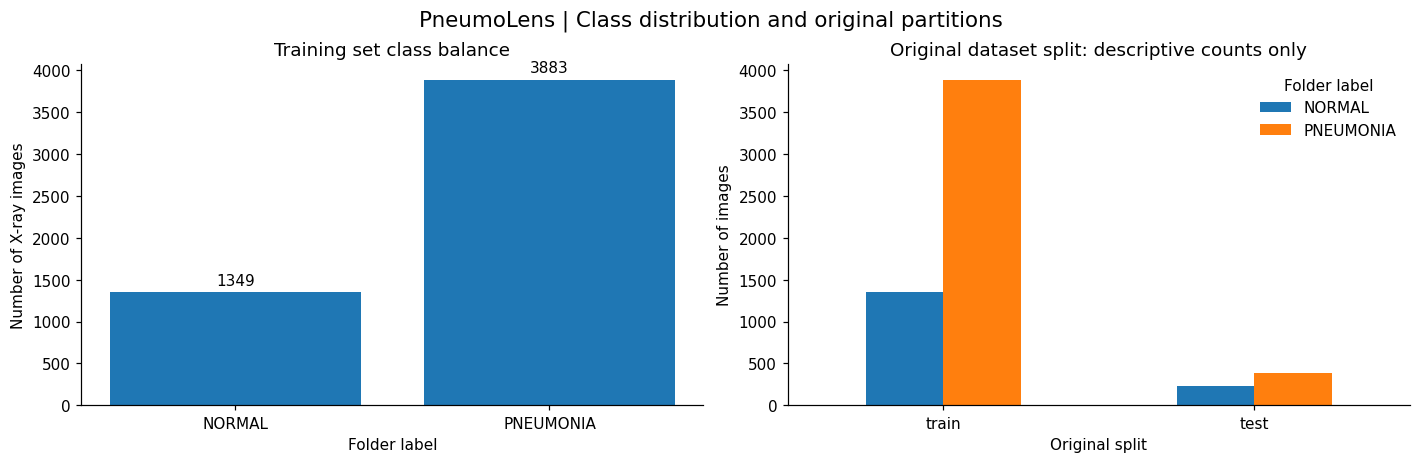

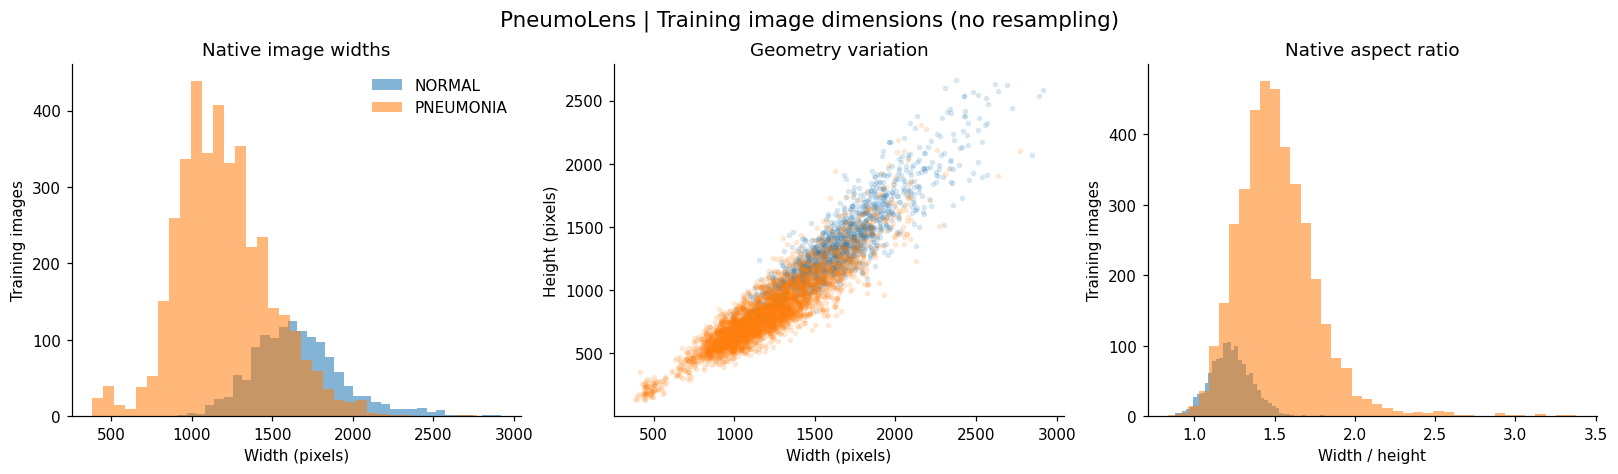

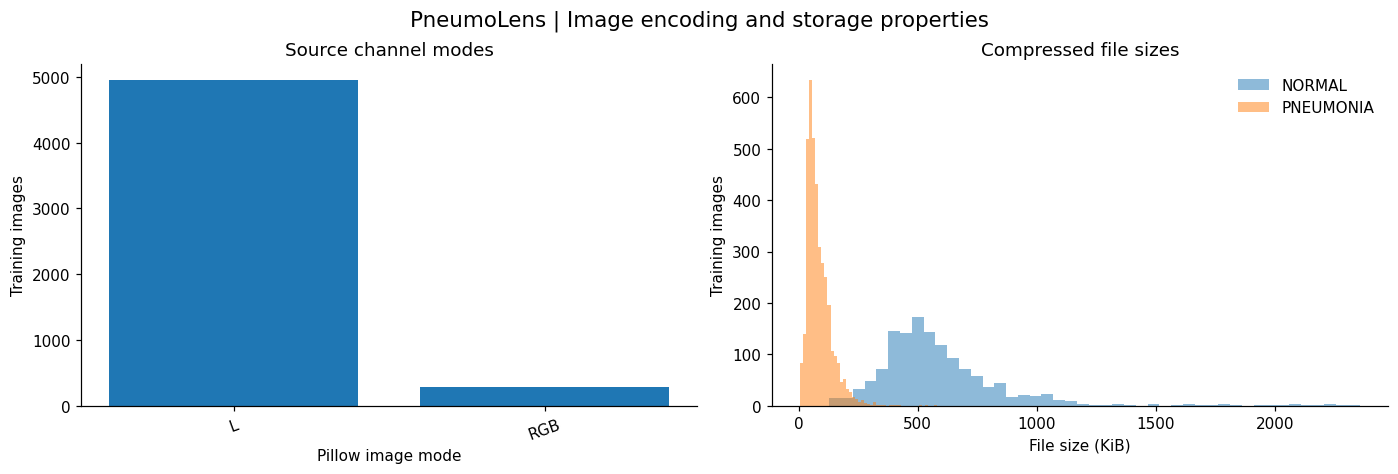

PosixPath('/kaggle/working/pneumolens_eda_phase02/project_files/reports/figures/phase2_03_channels_and_filesize.png')

In [7]:
def save_figure(fig: plt.Figure, filename: str, *, private: bool = False) -> Path:
    destination = (LOCAL_DATA_DIR if private else FIGURE_DIR) / filename
    fig.savefig(destination, bbox_inches='tight', dpi=170)
    plt.show()
    plt.close(fig)
    return destination

# Figure 1: class sizes and split composition
fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.1), layout='constrained')
train_values = train_class_table.set_index('folder_class')['train_images'].reindex(['NORMAL','PNEUMONIA'])
rectangles = axes[0].bar(train_values.index, train_values.values)
axes[0].set(title='Training set class balance', ylabel='Number of X-ray images', xlabel='Folder label')
axes[0].bar_label(rectangles, padding=3, fmt='%d')
plot_split = split_class_counts.reindex(columns=['NORMAL', 'PNEUMONIA'], fill_value=0)
plot_split.plot(kind='bar', ax=axes[1], rot=0)
axes[1].set(title='Original dataset split: descriptive counts only', ylabel='Number of images', xlabel='Original split')
axes[1].legend(title='Folder label', frameon=False)
fig.suptitle('PneumoLens | Class distribution and original partitions', fontsize=14)
save_figure(fig, 'phase2_01_class_and_split_counts.png')

# Figure 2: widths, heights and native aspect ratio, training only
fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.2), layout='constrained')
for cls in ['NORMAL','PNEUMONIA']:
    subset = train_meta.loc[train_meta.label.eq(cls)]
    axes[0].hist(subset['width'].dropna(), bins=35, alpha=0.55, label=cls)
    axes[1].scatter(subset['width'], subset['height'], s=7, alpha=0.13, label=cls)
    axes[2].hist(subset['aspect_ratio'].dropna(), bins=40, alpha=0.55, label=cls)
axes[0].set(title='Native image widths', xlabel='Width (pixels)', ylabel='Training images')
axes[1].set(title='Geometry variation', xlabel='Width (pixels)', ylabel='Height (pixels)')
axes[2].set(title='Native aspect ratio', xlabel='Width / height', ylabel='Training images')
axes[0].legend(frameon=False)
fig.suptitle('PneumoLens | Training image dimensions (no resampling)', fontsize=14)
save_figure(fig, 'phase2_02_train_dimensions.png')

# Figure 3: native color modes and compressed file sizes, training only
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.2), layout='constrained')
modes = train_meta['native_mode'].value_counts()
axes[0].bar(modes.index.astype(str), modes.values)
axes[0].set(title='Source channel modes', xlabel='Pillow image mode', ylabel='Training images')
axes[0].tick_params(axis='x', rotation=20)
for cls in ['NORMAL','PNEUMONIA']:
    axes[1].hist(train_meta.loc[train_meta.label.eq(cls), 'file_size_kb'].dropna(),
                 bins=45, alpha=0.5, label=cls)
axes[1].set(title='Compressed file sizes', xlabel='File size (KiB)', ylabel='Training images')
axes[1].legend(frameon=False)
fig.suptitle('PneumoLens | Image encoding and storage properties', fontsize=14)
save_figure(fig, 'phase2_03_channels_and_filesize.png')

## 8 · Figures: brightness, contrast, and grayscale distribution

The *equal-image-weight* histograms prevent larger radiographs from dominating the curve. These are approximate distributions of **256-pixel-side train thumbnails**, not original-resolution or padded model-input histograms. They support a review of visual variation, not clinical conclusions.

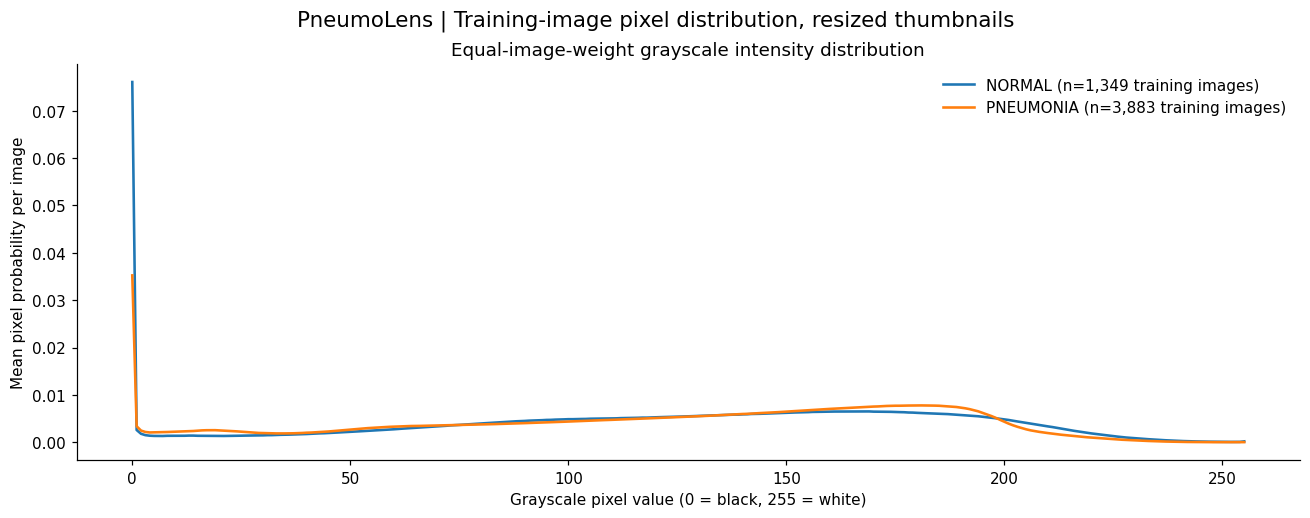

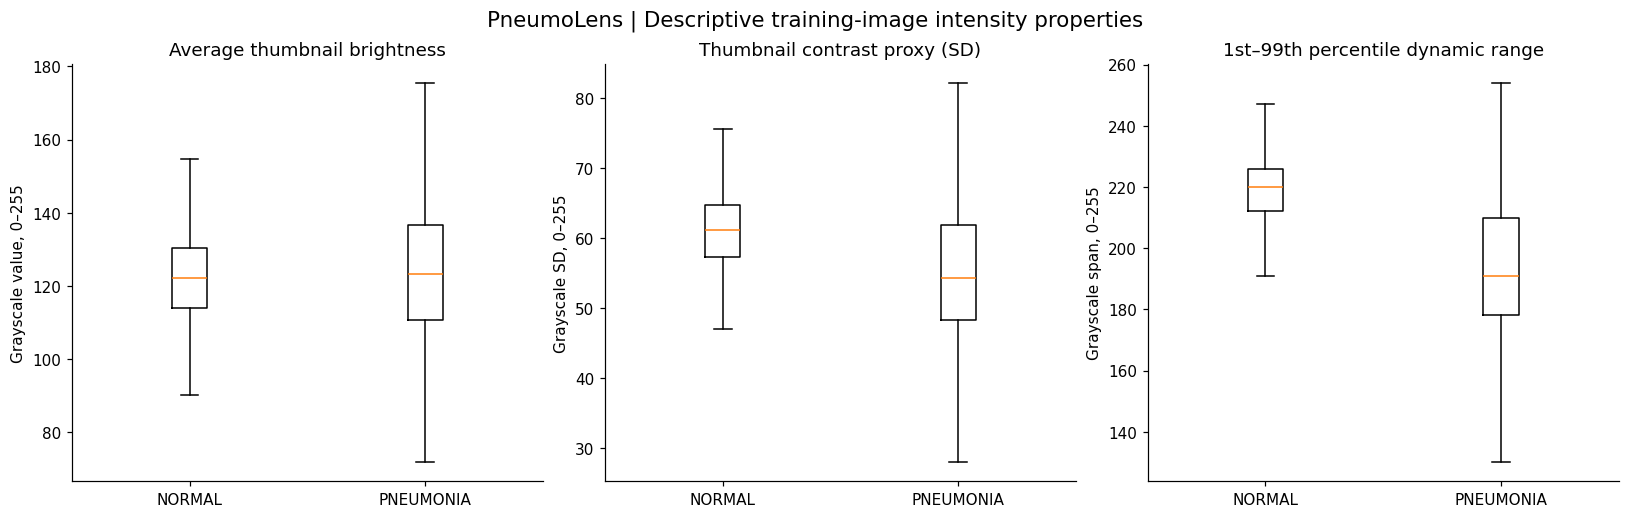

PosixPath('/kaggle/working/pneumolens_eda_phase02/project_files/reports/figures/phase2_05_train_brightness_and_contrast.png')

In [8]:
# Figure 4: 256-bin pixel density averaged equally over images in each class
fig, ax = plt.subplots(figsize=(11.8, 4.6), layout='constrained')
for cls in ['NORMAL', 'PNEUMONIA']:
    column = f'{cls.lower()}_equal_image_weight_probability'
    if hist_images[cls]:
        ax.plot(histogram_table['grayscale_bin_0_255'], histogram_table[column],
                label=f'{cls} (n={hist_images[cls]:,} training images)', linewidth=1.7)
ax.set(title='Equal-image-weight grayscale intensity distribution',
       xlabel='Grayscale pixel value (0 = black, 255 = white)', ylabel='Mean pixel probability per image')
ax.legend(frameon=False)
fig.suptitle('PneumoLens | Training-image pixel distribution, resized thumbnails', fontsize=14)
save_figure(fig, 'phase2_04_train_pixel_intensity.png')

# Figure 5: per-image brightness, variation, and estimated dynamic range
fig, axes = plt.subplots(1, 3, figsize=(14.7, 4.6), layout='constrained')
metric_panels = [
    ('mean_gray_8bit', 'Average thumbnail brightness', 'Grayscale value, 0–255'),
    ('std_gray_8bit', 'Thumbnail contrast proxy (SD)', 'Grayscale SD, 0–255'),
    ('range_p01_p99_8bit', '1st–99th percentile dynamic range', 'Grayscale span, 0–255'),
]
for axis, (metric, title, y_label) in zip(axes, metric_panels):
    arrays = [train_pixel.loc[train_pixel.label.eq(cls), metric].dropna().values
              for cls in ['NORMAL','PNEUMONIA']]
    if all(len(a) for a in arrays):
        axis.boxplot(arrays, positions=[1, 2], showfliers=False)
        axis.set_xticks([1, 2])
        axis.set_xticklabels(['NORMAL', 'PNEUMONIA'])
    else:
        axis.text(0.5, 0.5, 'Insufficient data', transform=axis.transAxes,
                  ha='center', va='center')
    axis.set(title=title, ylabel=y_label)
fig.suptitle('PneumoLens | Descriptive training-image intensity properties', fontsize=14)
save_figure(fig, 'phase2_05_train_brightness_and_contrast.png')

## 9 · Representative training X-rays and 224×224 letterbox sanity check

Show an **RNG-reproducible, class-balanced sample** of training images and a separate aspect-ratio-preserving 224×224 letterbox preview. These are visual engineering checks only. The sample gallery is saved under ignored `data/processed/` for **local review**, not under publishable `reports/figures/`.

The preview is **not yet** the final PyTorch transform: ImageNet normalization, augmentation and grayscale-to-three-channel conversion will be implemented and tested in Phase 3 (Preprocessing).

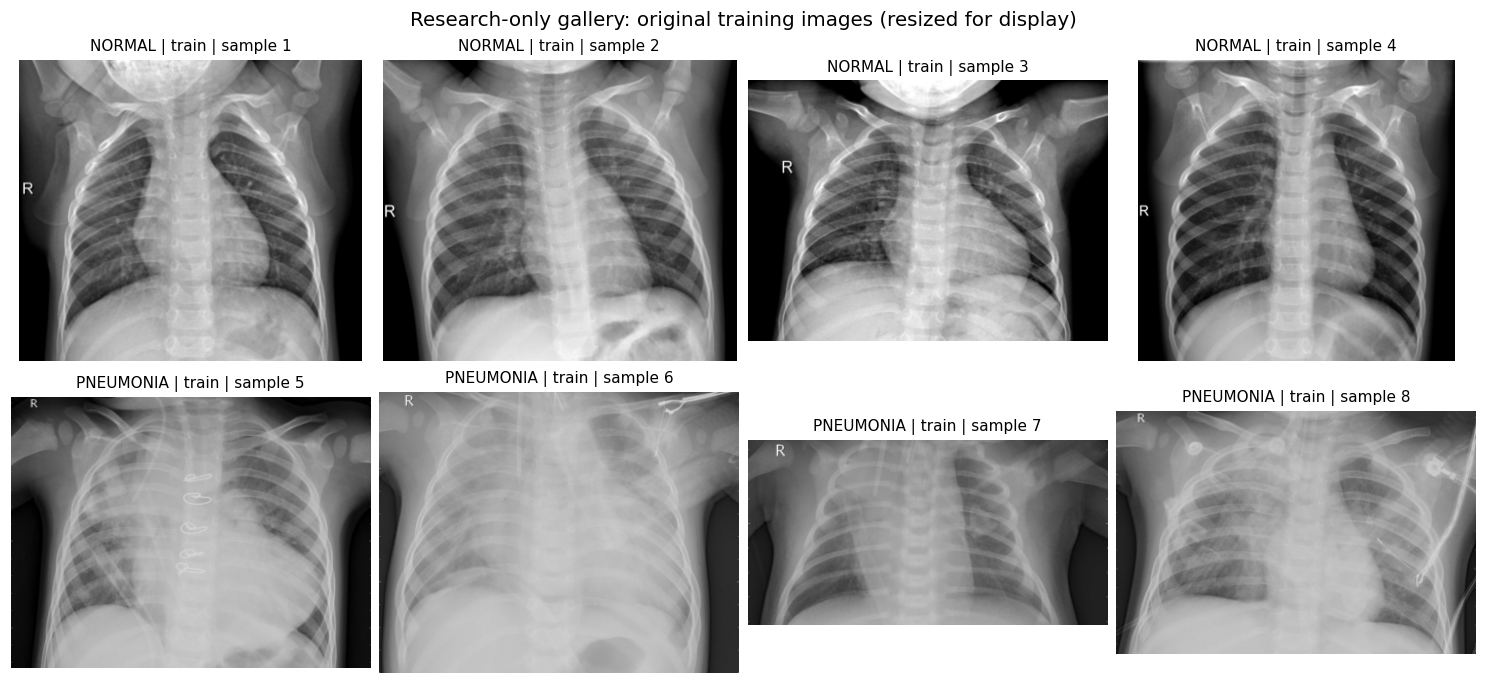

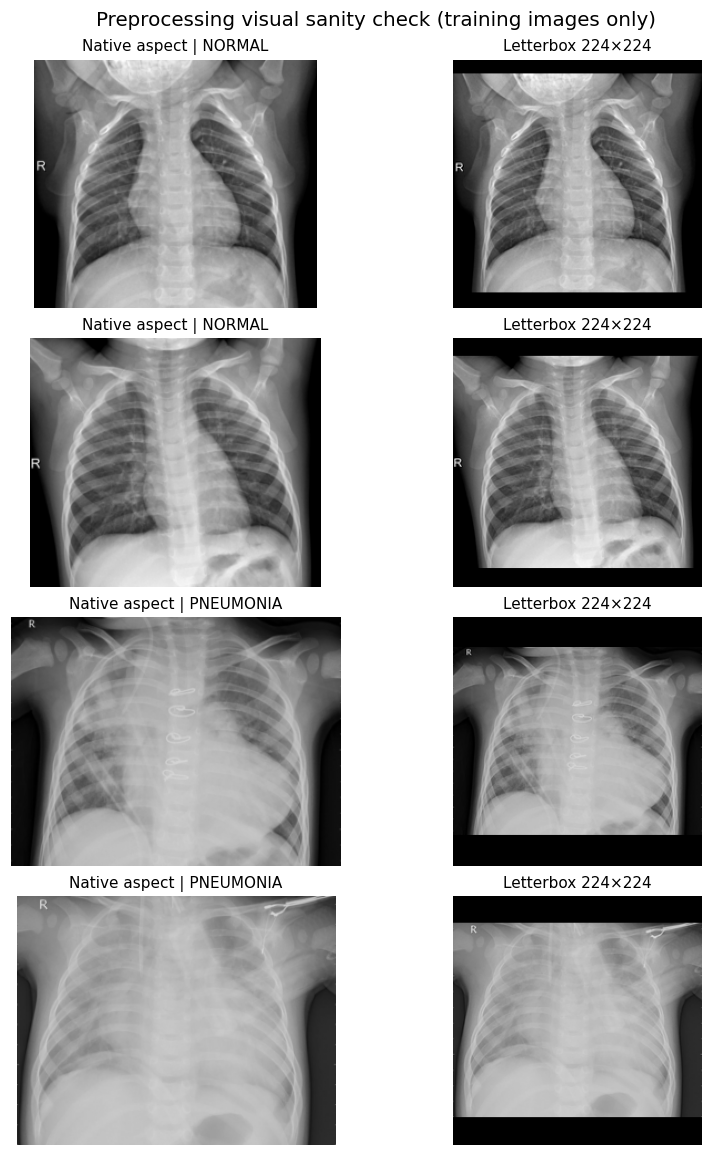

In [9]:
def read_grayscale_for_display(relative_path: str) -> Image.Image:
    with open_image_bytes(relative_path) as handle:
        with Image.open(handle) as image:
            return ImageOps.exif_transpose(image).convert('L')

def make_letterbox(image: Image.Image, size: int = 224, pad_value: int = 0) -> Image.Image:
    """Preserve native aspect ratio; never stretch the anatomy to a square."""
    reduced = image.copy()
    reduced.thumbnail((size, size), Image.Resampling.LANCZOS)
    canvas = Image.new('L', (size, size), color=int(pad_value))
    left = (size - reduced.width) // 2
    top = (size - reduced.height) // 2
    canvas.paste(reduced, (left, top))
    return canvas

sample_rows = []
for cls in ['NORMAL', 'PNEUMONIA']:
    candidates = train_pixel.loc[train_pixel['label'].eq(cls), 'relative_path'].to_list()
    if candidates:
        take = min(EXAMPLES_PER_CLASS, len(candidates))
        selected_indices = RNG.choice(len(candidates), size=take, replace=False)
        sample_rows.extend([{'class': cls, 'relative_path': candidates[int(i)]}
                            for i in selected_indices])

if sample_rows:
    ncols = 4
    nrows = math.ceil(len(sample_rows) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(13.4, 3.1 * nrows), squeeze=False, layout='constrained')
    for axis in axes.flat:
        axis.axis('off')
    for i, sample in enumerate(sample_rows):
        img = read_grayscale_for_display(sample['relative_path'])
        img.thumbnail((350, 350), Image.Resampling.BILINEAR)
        axis = axes.flat[i]
        axis.imshow(img, cmap='gray', vmin=0, vmax=255)
        axis.set_title(f"{sample['class']} | train | sample {i+1}", fontsize=10)
        axis.axis('off')
    fig.suptitle('Research-only gallery: original training images (resized for display)', fontsize=13)
    save_figure(fig, 'phase2_train_gallery_PRIVATE.png', private=True)

    preview_rows = ([sample for sample in sample_rows if sample['class'] == 'NORMAL'][:2]
                    + [sample for sample in sample_rows if sample['class'] == 'PNEUMONIA'][:2])
    fig, axes = plt.subplots(len(preview_rows), 2, figsize=(7.3, 2.6 * len(preview_rows)),
                             squeeze=False, layout='constrained')
    for row_idx, sample in enumerate(preview_rows):
        original = read_grayscale_for_display(sample['relative_path'])
        shown = original.copy()
        shown.thumbnail((300, 225), Image.Resampling.BILINEAR)
        axes[row_idx, 0].imshow(shown, cmap='gray', vmin=0, vmax=255)
        axes[row_idx, 1].imshow(make_letterbox(original, MODEL_PREVIEW_SIDE),
                                cmap='gray', vmin=0, vmax=255)
        axes[row_idx, 0].set_title(f"Native aspect | {sample['class']}", fontsize=10)
        axes[row_idx, 1].set_title(f'Letterbox {MODEL_PREVIEW_SIDE}×{MODEL_PREVIEW_SIDE}', fontsize=10)
        for ax in axes[row_idx]:
            ax.axis('off')
    fig.suptitle('Preprocessing visual sanity check (training images only)', fontsize=13)
    save_figure(fig, 'phase2_letterbox_preview_PRIVATE.png', private=True)
else:
    print('No readable train images available for visual sampling. EDA gate will not pass.')

## 10 · Save validated outputs and determine EDA completion gate

The gate passes only when images can be discovered, split/class labels are recognized, training image metadata is readable, and every training X-ray has a successful pixel profile. **Passing the EDA gate does not approve model training.** Patient-level identity and the validation split remain unresolved Phase 1 methodology decisions.

In [10]:
# Summary tables: no filenames or individual image identifiers in GitHub-publishable tables.
summary_tables = {
    'phase2_split_class_counts.csv': split_class_counts.reset_index().rename(columns={'original_split': 'original_split'}),
    'phase2_train_class_balance.csv': train_class_table,
    'phase2_source_channel_modes.csv': mode_count_table,
    'phase2_train_geometry_summary.csv': train_geometry_table,
    'phase2_train_intensity_summary.csv': train_intensity_table,
    'phase2_filename_subtype_tokens_UNVERIFIED.csv': subtype_table,
    'phase2_train_intensity_histogram.csv': histogram_table,
    'phase2_train_review_flag_counts.csv': quality_flag_table,
}
for filename, frame in summary_tables.items():
    if isinstance(frame.columns, pd.MultiIndex):
        frame = frame.copy()
        frame.columns = ['_'.join(str(x) for x in c if str(x)) for c in frame.columns]
    frame.to_csv(TABLE_DIR / filename, index=False)

# File-level records are intentionally stored in locally ignored data/processed/.
profile.to_csv(LOCAL_DATA_DIR / 'phase2_train_and_header_profile_PRIVATE.csv', index=False)
failures = profile.loc[profile['header_error'].ne('') | profile['pixel_analysis_error'].ne(''),
                       ['relative_path', 'original_split', 'label', 'header_error', 'pixel_analysis_error']]
failures.to_csv(LOCAL_DATA_DIR / 'phase2_read_failures_PRIVATE.csv', index=False)
flagged = train_pixel.loc[train_pixel['quality_flags'].ne(''),
                          ['relative_path', 'label', 'quality_flags', 'width','height',
                           'mean_gray_8bit','std_gray_8bit']]
flagged.to_csv(LOCAL_DATA_DIR / 'phase2_review_candidates_PRIVATE.csv', index=False)

train_unknown = int(((profile['original_split'] == 'train') & (profile['label'] == 'UNKNOWN')).sum())
train_header_failed = int(((profile['original_split'] == 'train') &
                           profile['header_error'].ne('')).sum())
source_unrecognized = int(((inventory['original_split'] == 'UNKNOWN') |
                           (inventory['label'] == 'UNKNOWN')).sum())
completion_checks = {
    'one_chest_xray_dataset_selected': True,
    'at_least_one_train_normal_and_pneumonia': bool(
        set(train_class_table.loc[train_class_table['train_images'].gt(0), 'folder_class'])
        == {'NORMAL', 'PNEUMONIA'}),
    'all_source_images_have_recognized_split_and_class': source_unrecognized == 0,
    'no_conflicting_filename_class_tags': filename_conflicts == 0,
    'all_source_image_headers_readable': header_failures == 0,
    'all_original_train_headers_readable': train_header_failed == 0,
    'all_original_train_pixels_profiled': train_success == train_expected,
    'test_pixels_not_used_for_eda': bool(
        profile.loc[profile['original_split'].eq('test'), 'pixel_analysis_ok'].eq(False).all()),
}
eda_gate = 'PASS_FOR_PHASE3_PREPROCESSING_PLANNING' if all(completion_checks.values()) else 'NEEDS_REVIEW'

n_total = int(len(inventory))
n_train = int(inventory['original_split'].eq('train').sum())
n_val = int(inventory['original_split'].eq('val').sum())
n_test = int(inventory['original_split'].eq('test').sum())
n_train_normal = int(((inventory['original_split'] == 'train') &
                      (inventory['label'] == 'NORMAL')).sum())
n_train_pneu = int(((inventory['original_split'] == 'train') &
                    (inventory['label'] == 'PNEUMONIA')).sum())
imbalance_ratio = round(n_train_pneu / n_train_normal, 4) if n_train_normal else None
train_mean_of_means = float(train_pixel['mean_gray_8bit'].mean()) if train_success else None
train_mean_of_stds = float(train_pixel['std_gray_8bit'].mean()) if train_success else None

warnings_list = []
if audit_reference_mismatches:
    warnings_list.append('Attached dataset differs from the Phase 1 split counts: ' +
                         '; '.join(audit_reference_mismatches))
if invalid_labeled_rows:
    warnings_list.append(f'{invalid_labeled_rows} CXR image(s) have unknown source split or folder class')
if filename_conflicts:
    warnings_list.append(f'{filename_conflicts} folder vs filename class mismatches')
if train_header_failed:
    warnings_list.append(f'{train_header_failed} training file header(s) unreadable')
if pixel_failed:
    warnings_list.append(f'{pixel_failed} training file(s) failed full pixel analysis')
if not n_val:
    warnings_list.append('No existing validation partition; Phase 2 DOES NOT create one')
warnings_list.append('Patient-level independence remains unverified; filename numeric tokens are NOT verified patient IDs')
warnings_list.append('Phase 1 flagged exact duplicates and many dHash candidates; review them before approving training splits')
warnings_list.append('No external validation or clinical reliability can be claimed from this single dataset')

preprocessing_proposal = {
    'target_input_size': [MODEL_PREVIEW_SIDE, MODEL_PREVIEW_SIDE],
    'aspect_handling': 'Preserve aspect ratio; resize/letterbox rather than stretch or aggressive crop',
    'source_channels': 'Deterministically convert to grayscale then replicate to RGB for ImageNet-pretrained backbones',
    'normalization': 'Choose per-backbone normalization in Phase 3; EDA statistics are not model-transform moments',
    'augmentation': 'Mild train-only rotation/translation/brightness/contrast; avoid vertical flips and aggressive crops',
    'imbalance': 'Compute loss weights or a weighted sampler from the approved training subset only',
    'split_policy': 'Original test locked; do not construct val from unverified numeric filename groups',
}

summary = {
    'project': 'PneumoLens', 'github_phase': 'Phase 2 - EDA',
    'notebook': '02_EDA.ipynb',
    'executed_at_utc': datetime.now(timezone.utc).isoformat(),
    'selected_input': str(SOURCE['path']), 'input_kind': SOURCE['kind'],
    'zip_subfolder': SOURCE['prefix'],
    'analysis_scope': 'train-only pixel statistics and image galleries; test file counts and headers only',
    'observed_image_count': n_total,
    'original_splits': {'train': n_train, 'val': n_val, 'test': n_test},
    'train_label_counts': {'NORMAL': n_train_normal, 'PNEUMONIA': n_train_pneu},
    'train_pneumonia_to_normal_ratio': imbalance_ratio,
    'train_expected_pixel_images': train_expected,
    'train_decoded_pixel_images': train_success,
    'train_pixel_error_count': pixel_failed,
    'source_header_error_count': header_failures,
    'unknown_folder_label_or_split_count': source_unrecognized,
    'folder_filename_conflict_count': filename_conflicts,
    'phase1_reference_mismatches': audit_reference_mismatches,
    'train_mean_of_thumbnail_means_8bit': train_mean_of_means,
    'train_mean_of_thumbnail_stds_8bit': train_mean_of_stds,
    'thumbnail_longest_side': MAX_ANALYSIS_SIDE,
    'train_heuristic_review_flag_counts': quality_flag_counts,
    'sampled_training_gallery_images': len(sample_rows),
    'seed': SEED,
    'image_mode_counts_all': {str(k): int(v) for k, v in profile['native_mode'].value_counts().items()},
    'completion_checks': completion_checks, 'eda_completion_gate': eda_gate,
    'training_split_approved': False,
    'preprocessing_proposal_NOT_FINAL': preprocessing_proposal,
    'warnings': warnings_list,
    'libraries': {'python': sys.version.split()[0], 'pandas': pd.__version__,
                  'numpy': np.__version__, 'pillow': Image.__version__, 'matplotlib': matplotlib.__version__},
}
(REPORT_DIR / 'eda_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
print('EDA completion gate:', eda_gate)
print('Training split approved?', False)
print('Files staged under:', PROJECT_FILES)

EDA completion gate: PASS_FOR_PHASE3_PREPROCESSING_PLANNING
Training split approved? False
Files staged under: /kaggle/working/pneumolens_eda_phase02/project_files


## 11 · Research report and engineering interpretation

A concise report is generated from the **observed** outputs, rather than from expected numbers. It documents dataset scope, split/class imbalance, geometry, modes, training-only intensity analysis, flagged limitations, a provisional preprocessing plan, and the Phase 2 completion gate.

In [11]:
def markdown_table(headers: list[str], records: list[list]) -> str:
    lines = ['| ' + ' | '.join(map(str, headers)) + ' |',
             '| ' + ' | '.join('---' for _ in headers) + ' |']
    lines += ['| ' + ' | '.join(str(value) for value in record) + ' |' for record in records]
    return '\n'.join(lines)

class_rows = []
for split in split_class_counts.index:
    class_rows.append([split,
                       int(split_class_counts.loc[split, 'NORMAL']) if 'NORMAL' in split_class_counts.columns else 0,
                       int(split_class_counts.loc[split, 'PNEUMONIA']) if 'PNEUMONIA' in split_class_counts.columns else 0,
                       int(split_class_counts.loc[split].sum())])
mode_rows = [[str(mode), int(count)]
             for mode, count in profile['native_mode'].value_counts().items()]
flag_rows = [[name, count, f'{100 * count / max(1, train_success):.2f}%']
             for name, count in quality_flag_counts.items()]
warning_lines = '\n'.join(f'- {warning}' for warning in warnings_list)
check_lines = '\n'.join(f"- {'PASS' if passed else 'FAIL'}: {check.replace('_', ' ')}"
                        for check, passed in completion_checks.items())

report = f'''# PneumoLens — Phase 2: Exploratory Data Analysis

**Status:** {eda_gate}  
**Scope:** pediatric chest X-rays; folder-labeled NORMAL/PNEUMONIA; educational research only  
**Source:** `{SOURCE['path']}` ({SOURCE['kind']})  
**Notebook:** `02_EDA.ipynb`  
**Date (UTC):** {summary['executed_at_utc']}

## 1. Dataset inventory and source partitions

A total of **{n_total:,} CXR images** were discovered in the selected chest X-ray tree. Images from unrelated OCT folders were not included. Source partitions were preserved and were not shuffled, resampled or re-labeled. Test-set images were not used for pixel-intensity statistics, galleries, or preprocessing selection.

{markdown_table(['Original split', 'NORMAL', 'PNEUMONIA', 'Total images'], class_rows)}

The original training set contains **{n_train_normal:,} NORMAL** and **{n_train_pneu:,} PNEUMONIA** images (pneumonia-to-normal ratio: **{imbalance_ratio if imbalance_ratio is not None else 'undefined'}:1**). Imbalance handling, if used, must be fitted on the *future approved training subset*, not test or validation data.

## 2. Native geometry and channel modes

X-ray image **headers** were read for all partitions: **{header_failures}** header failure(s). Width, height, aspect ratio and original image modes were recorded. All geometry/encoding figures used for design comparisons draw on original **train** images.

{markdown_table(['Image mode', 'Number of source images (all splits)'], mode_rows)}

The train-only size distributions and aspect-ratio scatter are in `reports/figures/phase2_02_train_dimensions.png`. Large native variation supports testing **aspect-preserving** resize plus padding rather than squashing every source to a 224×224 square.

## 3. Train-only pixel properties and review flags

Successfully profiled **{train_success:,}/{train_expected:,}** labeled training images with an aspect-preserving, up-to-{MAX_ANALYSIS_SIDE}-pixel-side grayscale thumbnail. These descriptive values are not full-resolution intensity measurements or final model-input normalization statistics.

Mean of per-image training thumbnail means: **{f'{train_mean_of_means:.2f}' if train_mean_of_means is not None else 'N/A'}/255**. Mean of per-image thumbnail intensity standard deviations: **{f'{train_mean_of_stds:.2f}' if train_mean_of_stds is not None else 'N/A'}/255**. See published aggregate tables for class-wise distributions and local, git-ignored `data/processed/` for image-level review records.

{markdown_table(['Heuristic review flag', 'Training images', 'Fraction of decoded train'], flag_rows)}

Flags may overlap; they do **not** prove corruption, artifacts, poor medical quality, or exclusion eligibility. No image was automatically dropped.

## 4. Provisional preprocessing decisions (NOT final training settings)

- Use **224×224** as a reasonable first baseline input resolution, subject to visual inspection.
- Preserve aspect ratio using **letterboxing/padding**, not anisotropic stretching or aggressive cropping.
- Handle both grayscale and RGB source files deterministically; for a pretrained 3-channel CNN, consider grayscale-to-3-channel replication.
- Use the backbone's declared normalization or derive statistics using the finalized *train-only* transform; do not reuse pre-padding EDA moments blindly.
- Restrict mild geometric/brightness augmentation to the approved training split; avoid vertical flips.
- Address the observed class imbalance only with training-specific loss weighting/sampling.
- Keep original test locked and do **not** treat the numeric filename tokens as verified patient IDs.

## 5. Completion checks

{check_lines}

**EDA gate: {eda_gate}.** This gate is independent of approval to begin model training.

## 6. Open methodological limitations

{warning_lines}

The label PNEUMONIA and the filename tokens BACTERIAL/VIRAL are dataset labels, not microbiologically verified pathogen diagnoses. Image-level descriptive findings do not establish clinical accuracy, patient independence, or external validity. Pixel distributions can be affected by cropping, contrast, acquisition pipelines and text/edge artifacts.

## 7. File locations

- Summary: `reports/Phase 2/eda_summary.json`
- Aggregate CSVs: `reports/tables/phase2_*.csv`
- Reproducible charts: `reports/figures/phase2_*.png`
- Local-only image-level review and private gallery: `data/processed/phase2_*PRIVATE*`

## 8. Phase 3 handoff

Before starting **Phase 3: Preprocessing**, review the EDA figures, verify label and modality scope, and finalize a deterministic 224×224 transform with a visual sanity check. **Do not train or tune on the test partition.** Resolve Phase 1 patient/group-independence and near-duplicate findings before choosing a validation split and starting benchmark experiments.
'''
(REPORT_DIR / 'eda_report.md').write_text(report, encoding='utf-8')
print(report[:4500])

# PneumoLens — Phase 2: Exploratory Data Analysis

**Status:** PASS_FOR_PHASE3_PREPROCESSING_PLANNING  
**Scope:** pediatric chest X-rays; folder-labeled NORMAL/PNEUMONIA; educational research only  
**Source:** `/kaggle/input/datasets/srabondcosta/pneumonia/ZhangLabData/CellData/chest_xray` (directory)  
**Notebook:** `02_EDA.ipynb`  
**Date (UTC):** 2026-11-22T06:24:51.332541+00:00

## 1. Dataset inventory and source partitions

A total of **5,856 CXR images** were discovered in the selected chest X-ray tree. Images from unrelated OCT folders were not included. Source partitions were preserved and were not shuffled, resampled or re-labeled. Test-set images were not used for pixel-intensity statistics, galleries, or preprocessing selection.

| Original split | NORMAL | PNEUMONIA | Total images |
| --- | --- | --- | --- |
| train | 1349 | 3883 | 5232 |
| test | 234 | 390 | 624 |

The original training set contains **1,349 NORMAL** and **3,883 PNEUMONIA** images (pneumonia-to-normal rat

## 12 · One-click handoff ZIP, already arranged for your Windows project

The ZIP contains `reports/Phase 2/`, `reports/tables/`, `reports/figures/`, and `data/processed/` **at its root**. Extract it **directly into**:

`E:\CODE\Python\ALL Project\Computer Vision\PneumoLens`

The existing Phase 1 files are untouched. Keep the contents of `data/processed/` local and Git-ignored. The notebook itself is saved/downloaded separately as `notebooks/02_EDA.ipynb`.

In [12]:
# Final self-check, build a single portable ZIP, and show a download link.
expected_reports = [REPORT_DIR / 'eda_report.md', REPORT_DIR / 'eda_summary.json']
if not all(path.is_file() for path in expected_reports):
    raise RuntimeError('A required report is missing; refusing to package incomplete output.')
if not list(FIGURE_DIR.glob('phase2_*.png')):
    raise RuntimeError('No figures were generated; refusing to package incomplete output.')
if not list(TABLE_DIR.glob('phase2_*.csv')):
    raise RuntimeError('No summary tables were generated; refusing to package incomplete output.')

output_zip = WORK_DIR / 'PneumoLens_Phase2_EDA_Outputs.zip'
with zipfile.ZipFile(output_zip, mode='w', compression=zipfile.ZIP_DEFLATED, compresslevel=6) as package:
    files_to_package = sorted(path for path in PROJECT_FILES.rglob('*') if path.is_file())
    for path in files_to_package:
        package.write(path, arcname=path.relative_to(PROJECT_FILES).as_posix())

with zipfile.ZipFile(output_zip) as package:
    invalid_member = package.testzip()
    if invalid_member is not None:
        raise IOError(f'ZIP verification failed at: {invalid_member}')

print('\n' + '=' * 65)
print('PNEUMOLENS PHASE 2 — EDA EXPORT COMPLETE')
print('=' * 65)
print('EDA gate:', eda_gate)
print('Files in ZIP:', len(files_to_package))
print('ZIP size:', f'{output_zip.stat().st_size / (1024 * 1024):.2f} MiB')
print('ZIP:', output_zip)
print('Extract into: E:\\CODE\\Python\\ALL Project\\Computer Vision\\PneumoLens')
print('Save this notebook separately to: notebooks/02_EDA.ipynb')
print('NOTE: EDA completion does not approve a train/validation split.')
display(FileLink(str(output_zip)))

if ARCHIVE is not None:
    ARCHIVE.close()


PNEUMOLENS PHASE 2 — EDA EXPORT COMPLETE
EDA gate: PASS_FOR_PHASE3_PREPROCESSING_PLANNING
Files in ZIP: 20
ZIP size: 2.52 MiB
ZIP: /kaggle/working/pneumolens_eda_phase02/PneumoLens_Phase2_EDA_Outputs.zip
Extract into: E:\CODE\Python\ALL Project\Computer Vision\PneumoLens
Save this notebook separately to: notebooks/02_EDA.ipynb
NOTE: EDA completion does not approve a train/validation split.


/kaggle/working/pneumolens_eda_phase02/PneumoLens_Phase2_EDA_Outputs.zip